# 01 · Dataset overview + baseline

The notebook:
1. loads the **CheXpert dataset** (training and test set),
2. describes the dataset
3. runs **`densenet121-res224-chex`** (trained only on CheXpert, never saw NIH) on every image,
4. saves a **per-image table** with the model scores and a TP / FP / FN / TN column per finding,
5. computes the **baselines** that later analysis steps compare against:
   - **main baseline**: 3 findings vs. Google radiologist labels (AUROC, AUPRC, sensitivity, specificity, precision,
     confusion matrices, 95 % confidence intervals),
   - **second baseline**: 7 findings vs. NIH's own text-mined labels (noisier) (???),
   - **output baseline**: what the model says for all 11 outputs (no labels needed) + `compare_runs()` for perturbations

The baseline is a reference point, not a finding.

1. *Add Input* → filter **Datasets** → **"CheXpert-v1.0-small"** (`ashery/chexpert`, 11.5 GB)
3. *Run all*. Set `LIMIT = 200` in the config first for a quick check.

**Outputs** in `/kaggle/working/` (Output panel → download):

| File | Content |
|---|---|
| `predictions_chex.csv` | one row per image: metadata, Google + NIH labels, model scores, outcomes |
| `baseline_metrics_chex.csv` | main baseline: 3 findings vs. Google labels, with 95 % CIs |
| `baseline_metrics_chex_nihlabels.csv` | second baseline: 7 findings vs. NIH text-mined labels |
| `baseline_outputs_chex.csv` | output baseline: all 11 outputs (share "yes", mean / median score) |
| `baseline_metrics_chexpert_valid.csv`, `..._heldout.csv` | CheXpert baselines (all 11 outputs) |
| `baseline_all_chex.csv` | all baselines in one long table |
| `predictions_chexpert_valid.csv`, `..._heldout.csv` | per-image scores on CheXpert |
| `run_info.json` | versions, settings, counts (reproducibility) |

In [2]:
import os, sys
try:
    import torchxrayvision
    print("torchxrayvision", torchxrayvision.__version__, "found in", sys.executable)
except ImportError:
    if os.path.exists("/kaggle"):
        # pinned to the commit we inspected (v1.5.7, 17.10.2026). Needs Settings -> Internet: On
        %pip install -q "git+https://github.com/mlmed/torchxrayvision@17726dd8f5e756eec3e5ae958281a289b05b1dae"
        import torchxrayvision
        print("installed torchxrayvision", torchxrayvision.__version__)
    else:
        raise ImportError(f"torchxrayvision is not installed for this kernel ({sys.executable}). "
                          "Locally: select the project's .venv kernel (VS Code: top right -> Select Kernel).")

torchxrayvision 1.5.7 found in c:\Users\klara\miniforge3\envs\msc-venv\python.exe


## Config
Everything you might want to change is here.

In [1]:
import os
ON_KAGGLE = os.path.exists("/kaggle")
# Kaggle: full run. Locally (from shared/): the sample in data/kaggle_input_sample (100 NIH + 7 CheXpert images)
INPUT_ROOT  = "/kaggle/input"   if ON_KAGGLE else os.path.abspath("../data/kaggle_input_sample")
WORK        = "/kaggle/working" if ON_KAGGLE else os.path.abspath("../data/local_run")
LIMIT       = None              if ON_KAGGLE else 1000     # None = all 4,376 images
LINK_DIR    = os.path.join("/tmp", "nih_google_links")   # temporary, not saved as output

WEIGHTS     = "densenet121-res224-chex"   # trained only on CheXpert -> NIH is an external test set
TAG         = "chex"                      # short name used in file and column names
THRESHOLD   = 0.5                         # the model's own operating point (see section 6). Never tuned on NIH

FINDINGS    = {g: g for g in ['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Pneumonia', 'Cardiomegaly', 'Lung Lesion', 'Fracture',
                                          'Lung Opacity', 'Enlarged Cardiomediastinum']} # from model.pathologies
# Second, noisier reference: NIH's own text-mined labels for the same images -> model output -- IRRELEVANT IN NON-NIH ITERATION
NIH_FINDINGS = {g: g for g in ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion",
                                "Pneumonia", "Pneumothorax"]}
RUN_CHEX_EVAL      = True                 # section 12: run the model on CheXpert valid + reconstructed held-out
CHEX_HELDOUT_VIEWS = ["PA"]               # loader default, which the training script uses for CheXpert (see 12)

N_BOOT      = 1000                        # bootstrap resamples (by patient) for the 95 % CIs
SEED        = 0
BATCH_SIZE  = 32
SAVE_THUMBS = True
THUMB_SIZE  = 512
os.makedirs(WORK, exist_ok=True)
print("Kaggle" if ON_KAGGLE else "local", "| input:", INPUT_ROOT, "| output:", WORK, "| limit:", LIMIT)

local | input: c:\Users\klara\Documents\school_and_university\linz_jku\UE_visAI\data\kaggle_input_sample | output: c:\Users\klara\Documents\school_and_university\linz_jku\UE_visAI\data\local_run | limit: 1000


In [3]:
import glob, json, time, platform, shutil
import numpy as np, pandas as pd, torch, torchvision
import matplotlib.pyplot as plt
import torchxrayvision as xrv
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torchxrayvision", xrv.__version__, "| torch", torch.__version__, "| device", device)

# one fixed colour per entity, used in every figure (Okabe-Ito, colour-blind safe, for C_DATA; viridis palette for C_FIND)
C_DATA = {"NIH Google (test)": "#0072B2", "CheXpert (training)": "#E69F00"}
# not optimal but something's gotta give

C_FIND = {name : color for name, color in zip(FINDINGS,["#a6cee3","#1f78b4","#b2df8a","#33a02c","#fb9a99","#e31a1c","#fdbf6f","#ff7f00","#cab2d6","#6a3d9a","#ffff99","#b15928", "#000000"])}
C_NEG  = "#8c8c8c"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "figure.dpi": 110})

torchxrayvision 1.5.7 | torch 2.13.0 | device cpu


## 1 · Find the inputs
NIH spreads its PNGs over `images_001/images/` … `images_012/images/`. CheXpert is the folder that holds
`train.csv`, `valid.csv` and `train/`. Kaggle's mount path differs between versions, so we search for both.

In [4]:
img_dirs = sorted({d for depth in range(1, 5)
                   for d in glob.glob(os.path.join(INPUT_ROOT, *["*"] * depth, "train", "patient*","study*"))})

if not img_dirs:
    mounted = sorted(os.path.relpath(p, INPUT_ROOT) for p in glob.glob(os.path.join(INPUT_ROOT, "*", "*")))
    raise FileNotFoundError("No images_*/images folders found. Add the DATASET 'nih-chest-xrays/data' "
                            "(Add Input -> filter 'Datasets'), not a notebook. Mounted now: " + str(mounted[:20]))
chex_path = {}
for d in img_dirs:
    patient_id = os.path.basename(os.path.dirname(d))
    study_id = os.path.basename(d)

    for e in os.scandir(d):
        if e.is_file() and e.name.endswith(".jpg") and not e.name.startswith("._"):
            filename = e.name

            key = f"{patient_id}/{study_id}/{filename}"
            chex_path[key] = e.path
print(f"CheXpert: {len(img_dirs)} image folders, {len(chex_path):,} jpgs indexed (full dataset = 223,462)")

def find_chexpert(root):
    for depth in range(0, 5):
        for csv in glob.glob(os.path.join(root, *["*"] * depth, "train.csv")):
            d = os.path.dirname(csv)
            if os.path.isdir(os.path.join(d, "train")) and os.path.exists(os.path.join(d, "valid.csv")):
                return d
    return None

CHEX_DIR = find_chexpert(INPUT_ROOT)
# if CHEX_DIR:
#     chex_csv = pd.read_csv(os.path.join(CHEX_DIR, "train.csv"))
#     CHEX_SOURCE = f"Kaggle input ({CHEX_DIR})"
# else:
#     # same file, cell for cell (checked), shipped with torchxrayvision. Labels + metadata only, no images
#     chex_csv = pd.read_csv(os.path.join(os.path.dirname(xrv.__file__), "data", "chexpert_train.csv.gz"))
#     CHEX_SOURCE = "label file bundled with torchxrayvision (no images)"
# print(f"CheXpert: {len(chex_csv):,} rows from {CHEX_SOURCE}")

CheXpert: 187641 image folders, 223,414 jpgs indexed (full dataset = 223,462)


## 2 · Load the CheXpert data
Many patients have several images, so the confidence intervals later resample **patients**, not images.

In [5]:
transform = torchvision.transforms.Compose([
    xrv.datasets.XRayCenterCrop(),
    xrv.datasets.XRayResizer(224)
])

def chex_dataset(transform, data_aug=None):
    return xrv.datasets.CheX_Dataset(
        imgpath=CHEX_DIR,
        data_aug=data_aug,
        csvpath=os.path.join(CHEX_DIR, "train.csv"),
        views=["PA", "AP"],
        unique_patients=False,
        transform=transform
    )

rng = np.random.default_rng(42)


ds_baseline = chex_dataset(transform)
ds_baseline.csv["path_to_image"] =ds_baseline.csv["Path"].str[20:]
ds_baseline.csv.drop("Path", axis = 1)

n = len(ds_baseline)

bootstrap_idx = rng.choice(
    n,
    size=LIMIT,
    # size = n,
    replace=True
)

# Ground-truth labels


ds_bootstrap = xrv.datasets.SubsetDataset(
    ds_baseline,
    idxs=bootstrap_idx
)

print(ds_bootstrap)

GT_LABELS = list(ds_baseline.pathologies)

print("CheXpert labels:", GT_LABELS)


gt = pd.DataFrame(
    ds_bootstrap.labels.astype(int),
    columns=["gt_" + p.replace(" ", "_").replace("/", "_")
             for p in GT_LABELS]
)

meta = ds_bootstrap.csv.reset_index(drop=True).copy()
metadata_plus = pd.read_csv(
    os.path.join(CHEX_DIR, "df_chexpert_plus_240401.csv")
)


gcol = lambda g: "gt_" + g.replace(" ", "_").replace("/", "_")

meta = meta.rename(columns={
    "Path": "image_id",
    "Age": "age",
    "AP/PA": "view",
    "Frontal/Lateral": "image_type"
})

meta = meta.merge(
    metadata_plus,
    on="path_to_image",
    how="left",
    validate="many_to_one"
)

meta["sex"] = np.select(
    [
        meta["sex_male"] == 1,
        meta["sex_female"] == 1
    ],
    [
        "Male",
        "Female"
    ],
    default="Other/Unknown"
)

chex = pd.concat([meta, gt], axis=1)
chex["patient_id"] = chex["image_id"].str.extract(r"(patient\d+)")
GT_LABELS = list(ds_bootstrap.pathologies)
print(ds_bootstrap)
print("Google labels:", GT_LABELS)

{'Atelectasis': {0.0: 91, 1.0: 144},
 'Cardiomegaly': {0.0: 129, 1.0: 118},
 'Consolidation': {0.0: 162, 1.0: 59},
 'Edema': {0.0: 149, 1.0: 270},
 'Effusion': {0.0: 168, 1.0: 425},
 'Enlarged Cardiomediastinum': {0.0: 134, 1.0: 38},
 'Fracture': {0.0: 90, 1.0: 46},
 'Lung Lesion': {0.0: 93, 1.0: 30},
 'Lung Opacity': {0.0: 101, 1.0: 522},
 'Pleural Other': {0.0: 86, 1.0: 15},
 'Pneumonia': {0.0: 88, 1.0: 22},
 'Pneumothorax': {0.0: 271, 1.0: 88},
 'Support Devices': {0.0: 27, 1.0: 570}}
SubsetDataset num_samples=1000
└ of CheX_Dataset num_samples=191010 views=['PA', 'AP'] data_aug=None
CheXpert labels: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum', 'Fracture', 'Lung Lesion', 'Lung Opacity', 'Effusion', 'Pleural Other', 'Pneumonia', 'Pneumothorax', 'Support Devices']
{'Atelectasis': {0.0: 91, 1.0: 144},
 'Cardiomegaly': {0.0: 129, 1.0: 118},
 'Consolidation': {0.0: 162, 1.0: 59},
 'Edema': {0.0: 149, 1.0: 270},
 'Effusion': {0.0: 168, 1.0: 425},

## 3 · The test set

In [134]:
per_patient = chex.groupby("patient_id").size()

summary = pd.Series({
    "images": len(chex),
    "patients": chex.patient_id.nunique(),
    "images per patient (median / max)": (
        f"{per_patient.median():.0f} / {per_patient.max()}"
    ),
    "view AP / PA": (
        f"{(chex['view'] == 'AP').sum()} / "
        f"{(chex['view'] == 'PA').sum()}"
    ),
    "sex M / F": (
        f"{(chex.sex == 'Male').sum()} / "
        f"{(chex.sex == 'Female').sum()}"
    ),
    "race black / asian / pacific islander / native american / white / patient refused / unknown,other,nan" : (
        f"{(chex.race == 'Black').sum()} / "
        f"{(chex.race == 'Asian').sum()} / "
        f"{(chex.race == 'Pacific Islander').sum()} / "
        f"{(chex.race == 'Native American').sum()} / "
        f"{(chex.race == 'White').sum()} / "
        f"{(chex.race == 'Patient Refused').sum()} / "
        f"{(chex.race.isin(['Unknown', 'Other']).sum() + chex.race.isna().sum())}"
    ),
    "age median (IQR)": (
        f"{chex.age_years.median():.0f} "
        f"({chex.age_years.quantile(.25):.0f}–"
        f"{chex.age_years.quantile(.75):.0f})"
    ),
}, name="CheXpert")

chex = chex.loc[:, ~chex.columns.duplicated()]

summary.to_frame()

,CheXpert
images,20000
patients,14414
images per patient (median / max),1 / 13
view AP / PA,view 16911\nview 16911\ndtype: int64 / v...
sex M / F,11774 / 8226
"race black / asian / pacific islander / native american / white / patient refused / unknown,other,nan",1113 / 2222 / 266 / 61 / 11243 / 32 / 5063
age median (IQR),62 (49–75)


KeyError: 'age'

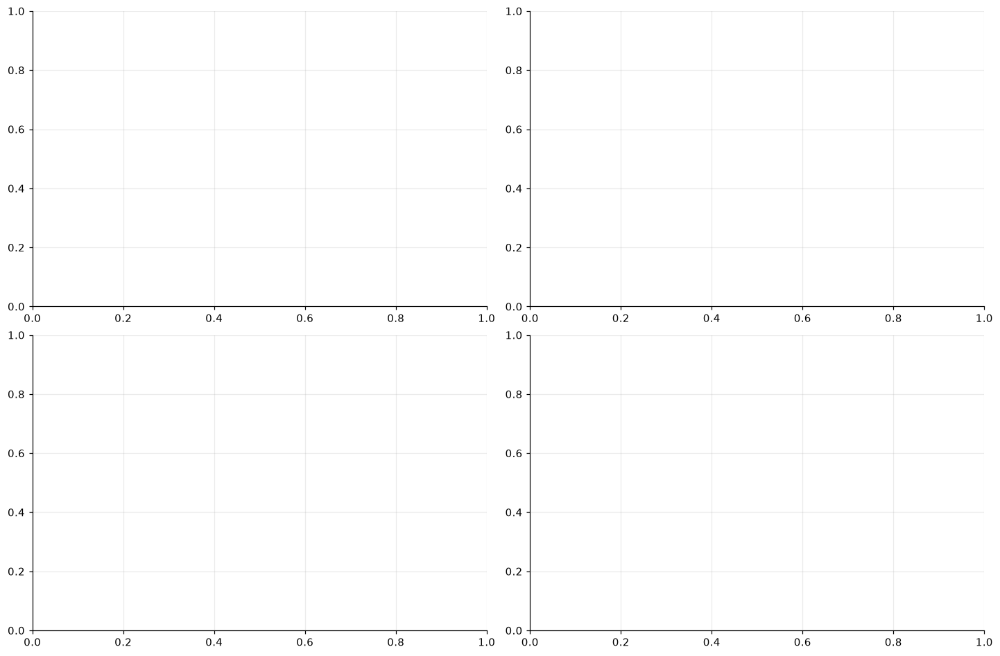

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), layout="constrained")

# a) Age distribution by sex
ax = axes[0, 0]
bins = np.arange(0, 101, 5)

for s, c, label in [
    ("Male", "#0072B2", "Male"),
    ("Female", "#E69F00", "Female")
]:
    values = chex.loc[chex.sex == s, "age"].dropna()
    ax.hist(
        values,
        bins=bins,
        histtype="step",
        lw=2,
        color=c,
        label=f"{label} (n={len(values):,})"
    )

ax.set_title("Age distribution by sex", loc="left", fontsize=11)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of images")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)


# b) Sex distribution
ax = axes[0, 1]

sex_counts = chex.sex.value_counts().reindex(["Male", "Female"]).fillna(0)
colors = ["#0072B2", "#E69F00"]

bars = ax.bar(
    ["Male", "Female"],
    sex_counts.values,
    color=colors,
    width=0.6
)

for bar, n in zip(bars, sex_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{n:,.0f} ({n / len(chex):.1%})",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("Sex distribution", loc="left", fontsize=11)
ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.2)


# c) Imaging view by sex
ax = axes[1, 0]

ct = pd.crosstab(chex["view"], chex["sex"])
ct = ct.reindex(columns=["Male", "Female"], fill_value=0)

x = np.arange(len(ct.index))
width = 0.36

for k, (s, c, label) in enumerate([
    ("Male", "#0072B2", "Male"),
    ("Female", "#E69F00", "Female")
]):
    bars = ax.bar(
        x + (k - 0.5) * width,
        ct[s],
        width=width,
        color=c,
        label=label
    )
    ax.bar_label(bars, fontsize=9)

ax.set_xticks(x, ct.index)
ax.set_title("Imaging view by sex", loc="left", fontsize=11)
ax.set_xlabel("Radiographic view")
ax.set_ylabel("Number of images")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)


# d) Images per patient
ax = axes[1, 1]

counts = per_patient.value_counts().sort_index()

ax.bar(
    counts.index,
    counts.values,
    color="#4d4d4d",
    width=0.8
)

ax.set_yscale("log")
ax.set_title("Images per patient", loc="left", fontsize=11)
ax.set_xlabel("Number of images per patient")
ax.set_ylabel("Number of patients (log scale)")
ax.grid(axis="y", alpha=0.2)


# Overall figure title
fig.suptitle(
    f"Dataset overview: {len(chex):,} images from "
    f"{chex.patient_id.nunique():,} patients",
    fontsize=13
)

plt.show()

**Label combinations and scanner proxy.** Which findings occur together, and the distinct pixel spacings
(different spacing ≈ different scanner or detector).

In [24]:
combo = chex[[gcol(g) for g in GT_LABELS]].apply(
    lambda r: " + ".join(g for g, v in zip(GT_LABELS, r) if v == 1) or "(none)", axis=1)
display(combo.value_counts().rename("images").to_frame().head(12))
# display(pd.crosstab(chex.pixel_spacing_x.round(3), chex['view'], margins=True, margins_name="total")
#           .rename_axis(index="pixel spacing x (mm)"))

,images
(none),83
Support Devices,77
Lung Opacity + Effusion + Support Devices,68
Lung Opacity,57
Edema + Lung Opacity + Effusion + Support Devices,43
Lung Opacity + Support Devices,41
Lung Opacity + Effusion,34
Effusion + Support Devices,24
Edema + Lung Opacity + Support Devices,22
Edema,20


CheXpert examples (only if the Kaggle CheXpert input is attached). Same layout as the NIH examples below.

## 5 · Look at the Chex images before running anything
Two examples per Google label plus two with none of the four findings.

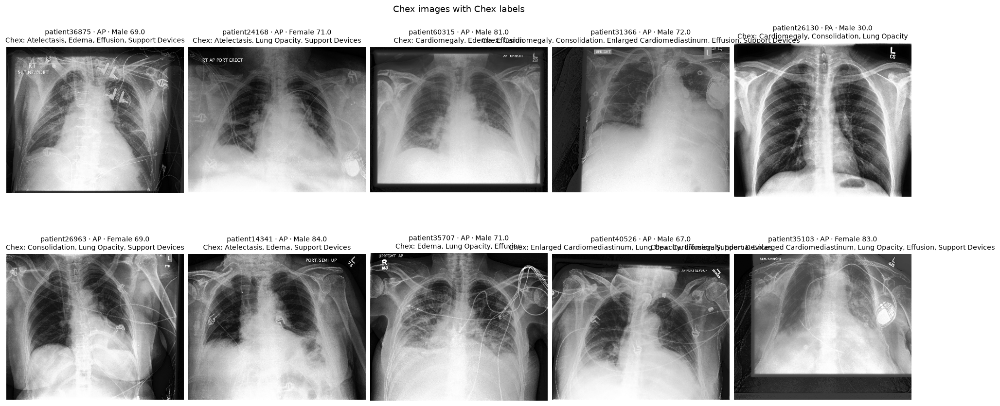

In [25]:
def gt_text(i):
    pos = [p for p, v in zip(GT_LABELS, ds_bootstrap.labels[i]) if v == 1]
    return ", ".join(pos) if pos else "none of the 4"

def load_raw(fname):
    return np.array(Image.open(chex_path[fname]).convert("L"))

rng = np.random.default_rng(SEED)
picks = []
for j in range(len(GT_LABELS)):
    pos = np.where(ds_bootstrap.labels[:, j] == 1)[0]
    picks += list(rng.choice(pos, min(2, len(pos)), replace=False))
neg = np.where(ds_bootstrap.labels.sum(1) == 0)[0]
picks += list(rng.choice(neg, min(2, len(neg)), replace=False))
picks = list(dict.fromkeys(picks))[:10]

fig, axes = plt.subplots(2, 5, figsize=(17, 8), layout="constrained")
for ax, i in zip(axes.flat, picks):
    r = chex.iloc[i]
    ax.imshow(load_raw(r.image_id[26:]), cmap="gray")
    ax.set_title(f"{r.image_id[26:38]} · {r['view']} · {r.sex} {r.age}\nChex: {gt_text(i)}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(picks):]:
    ax.axis("off")
fig.suptitle("Chex images with Chex labels", fontsize=12)
plt.show()

What the model actually sees: the file is 8-bit (0–255). `xrv` rescales it to **−1024…1024**, center-crops it to a
square and resizes it to **224×224**, one channel. Small findings (fractures, small nodules) lose a lot of detail.

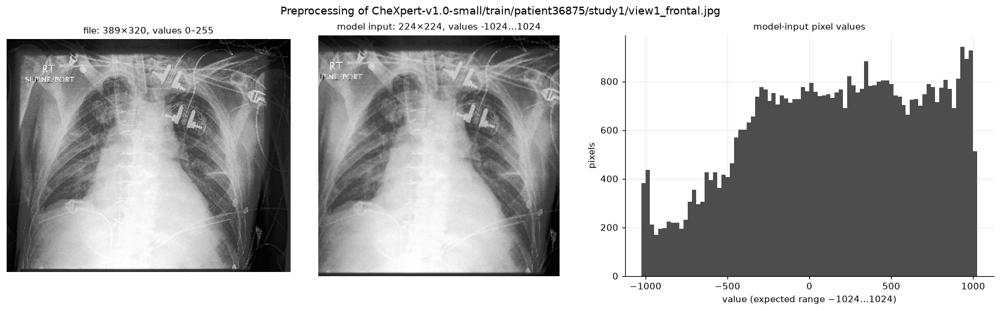

In [26]:
i = picks[0]
fname = chex.image_id.iloc[i]
raw_img = load_raw(fname[26:])
model_in = ds_bootstrap[i]["img"]                       # exactly what goes into the model
assert model_in.shape == (1, 224, 224)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained", gridspec_kw={"width_ratios": [1, 1, 1.3]})
axes[0].imshow(raw_img, cmap="gray")
axes[0].set_title(f"file: {raw_img.shape[1]}×{raw_img.shape[0]}, values {raw_img.min()}–{raw_img.max()}", fontsize=10)
axes[1].imshow(model_in[0], cmap="gray")
axes[1].set_title(f"model input: 224×224, values {model_in.min():.0f}…{model_in.max():.0f}", fontsize=10)
for ax in axes[:2]:
    ax.axis("off")
axes[2].hist(model_in.ravel(), bins=80, color="#4d4d4d")
axes[2].set_title("model-input pixel values", fontsize=10)
axes[2].set_xlabel("value (expected range −1024…1024)"); axes[2].set_ylabel("pixels")
fig.suptitle(f"Preprocessing of {fname}", fontsize=12)
plt.show()

## between 5 and 6 · Augment the data

We augment the dataset in the following two ways:
- downsampling the images
- adding noise

In [13]:
# adding Gaussian additive noise to the images
rng_noise = np.random.default_rng(SEED)
noise_sds = [50,100,250,500]

def add_noise(img, sd, rng):
    return (img + rng.normal(0,sd,img.shape)).astype(img.dtype)

ds_noise = {noise_sd :  xrv.datasets.SubsetDataset(
    chex_dataset(
    transform, data_aug = lambda img, sd = noise_sd: add_noise(img, sd = sd, rng = rng_noise)
    ),
    idxs=bootstrap_idx)
    for noise_sd in noise_sds}

In [6]:
# blur images
from scipy.ndimage.filters import gaussian_filter

blurring_levels = [0.1,0.75,1.5,3]

ds_blurred = {blurring_level :  xrv.datasets.SubsetDataset(
    chex_dataset(
    transform, data_aug = lambda img, a = blurring_level: gaussian_filter(img, a)
    ),
    idxs=bootstrap_idx)
    for blurring_level in blurring_levels}

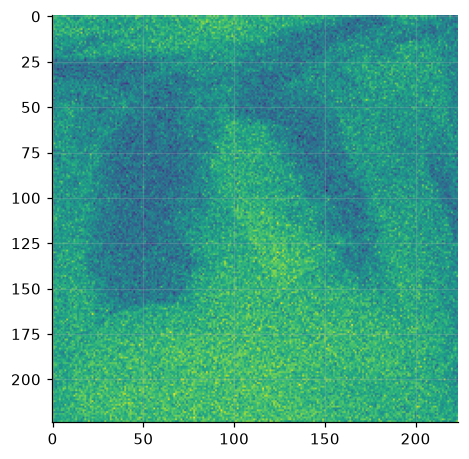

In [14]:
plt.imshow(ds_noise[500][0]["img"][0])

## 6 · Run the model
Per output we store two numbers:
- `chex__<label>`: the **calibrated** score, as `model(x)` returns it. The library rescales each output so that
  **0.5 = the model's own decision threshold** (`op_threshs`, chosen by the authors on CheXpert data).
  `> 0.5` means "predicted positive". This is what the baseline uses.
- `chex__<label>__raw`: the plain sigmoid probability before that rescaling.

###  6.1 Baseline

In [137]:
model = xrv.models.DenseNet(weights=WEIGHTS).to(device).eval()
labels = [l for l in model.pathologies if l]          # drop the empty slots of this checkpoint
keep = [i for i, l in enumerate(model.pathologies) if l]
op_threshs = model.op_threshs.cpu().numpy()[keep]
# assert all(m in labels for m in FINDINGS.values())
print(len(labels), "outputs:", labels)
col = lambda l: f"{TAG}__" + l.replace(" ", "_")

def run_model(dataset, name="", every=20):
    # one row per dataset item (same order): calibrated + raw score for every output
    cols = [col(l) for l in labels] + [col(l) + "__raw" for l in labels]
    if len(dataset) == 0:
        return pd.DataFrame(columns=cols, dtype=float)
    loader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                                         num_workers=2 if device == "cuda" else 0)
    raw, cal = [], []
    t0 = time.time()
    with torch.no_grad():
        for i, batch in enumerate(loader):
            x = batch["img"].to(device)
            p_raw = torch.sigmoid(model.classifier(model.features2(x)))
            p_cal = xrv.models.op_norm(p_raw, model.op_threshs.to(device))
            assert torch.allclose(p_cal, model(x), atol=1e-5)   # same as the model's normal forward pass
            raw.append(p_raw[:, keep].cpu().numpy())
            cal.append(p_cal[:, keep].cpu().numpy())
            if every and i % every == 0:
                print(f"{name} {min((i + 1) * BATCH_SIZE, len(dataset)):>6} / {len(dataset)}  {time.time() - t0:.0f}s")
    print(f"{name} done: {len(dataset):,} images in {time.time() - t0:.0f}s")
    return pd.DataFrame(np.hstack([np.concatenate(cal), np.concatenate(raw)]), columns=cols)

11 outputs: ['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Pneumonia', 'Cardiomegaly', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']


In [138]:
scores_baseline = run_model(ds_bootstrap, "CHEX")

CHEX     32 / 20000  4s
CHEX    672 / 20000  76s
CHEX   1312 / 20000  160s
CHEX   1952 / 20000  227s
CHEX   2592 / 20000  292s
CHEX   3232 / 20000  357s
CHEX   3872 / 20000  423s
CHEX   4512 / 20000  491s
CHEX   5152 / 20000  560s
CHEX   5792 / 20000  628s
CHEX   6432 / 20000  693s
CHEX   7072 / 20000  758s
CHEX   7712 / 20000  823s
CHEX   8352 / 20000  889s
CHEX   8992 / 20000  955s
CHEX   9632 / 20000  1021s
CHEX  10272 / 20000  1087s
CHEX  10912 / 20000  1153s
CHEX  11552 / 20000  1218s
CHEX  12192 / 20000  1283s
CHEX  12832 / 20000  1349s
CHEX  13472 / 20000  1415s
CHEX  14112 / 20000  1480s
CHEX  14752 / 20000  1547s
CHEX  15392 / 20000  1612s
CHEX  16032 / 20000  1679s
CHEX  16672 / 20000  1744s
CHEX  17312 / 20000  1811s
CHEX  17952 / 20000  1877s
CHEX  18592 / 20000  1943s
CHEX  19232 / 20000  2009s
CHEX  19872 / 20000  2075s
CHEX done: 20,000 images in 2088s


In [139]:
chex_scores = pd.concat(
    [
        chex.reset_index(drop=True),
        scores_baseline.reset_index(drop=True)
    ],
    axis=1
)

### 6.2 with perturbations

In [140]:
scores_noise = {noise_sd : run_model(ds_noise[noise_sd], "CHEX") for noise_sd in noise_sds}

CHEX     32 / 20000  4s
CHEX    672 / 20000  70s
CHEX   1312 / 20000  138s
CHEX   1952 / 20000  206s
CHEX   2592 / 20000  272s
CHEX   3232 / 20000  337s
CHEX   3872 / 20000  403s
CHEX   4512 / 20000  469s
CHEX   5152 / 20000  535s
CHEX   5792 / 20000  601s
CHEX   6432 / 20000  667s
CHEX   7072 / 20000  735s
CHEX   7712 / 20000  801s
CHEX   8352 / 20000  866s
CHEX   8992 / 20000  933s
CHEX   9632 / 20000  999s
CHEX  10272 / 20000  1065s
CHEX  10912 / 20000  1132s
CHEX  11552 / 20000  1198s
CHEX  12192 / 20000  1264s
CHEX  12832 / 20000  1330s
CHEX  13472 / 20000  1397s
CHEX  14112 / 20000  1463s
CHEX  14752 / 20000  1529s
CHEX  15392 / 20000  1594s
CHEX  16032 / 20000  1660s
CHEX  16672 / 20000  1727s
CHEX  17312 / 20000  1796s
CHEX  17952 / 20000  1863s
CHEX  18592 / 20000  1928s
CHEX  19232 / 20000  1994s
CHEX  19872 / 20000  2060s
CHEX done: 20,000 images in 2074s
CHEX     32 / 20000  3s
CHEX    672 / 20000  69s
CHEX   1312 / 20000  136s
CHEX   1952 / 20000  202s
CHEX   2592 / 20000 

In [141]:
scores_blurred = {blurring_level : run_model(ds_blurred[blurring_level], "CHEX") for blurring_level in blurring_levels}

CHEX     32 / 20000  3s
CHEX    672 / 20000  69s
CHEX   1312 / 20000  135s
CHEX   1952 / 20000  200s
CHEX   2592 / 20000  266s
CHEX   3232 / 20000  332s
CHEX   3872 / 20000  399s
CHEX   4512 / 20000  464s
CHEX   5152 / 20000  531s
CHEX   5792 / 20000  597s
CHEX   6432 / 20000  665s
CHEX   7072 / 20000  731s
CHEX   7712 / 20000  798s
CHEX   8352 / 20000  864s
CHEX   8992 / 20000  931s
CHEX   9632 / 20000  997s
CHEX  10272 / 20000  1063s
CHEX  10912 / 20000  1128s
CHEX  11552 / 20000  1194s
CHEX  12192 / 20000  1260s
CHEX  12832 / 20000  1325s
CHEX  13472 / 20000  1391s
CHEX  14112 / 20000  1457s
CHEX  14752 / 20000  1523s
CHEX  15392 / 20000  1588s
CHEX  16032 / 20000  1654s
CHEX  16672 / 20000  1719s
CHEX  17312 / 20000  1785s
CHEX  17952 / 20000  1850s
CHEX  18592 / 20000  1917s
CHEX  19232 / 20000  1983s
CHEX  19872 / 20000  2048s
CHEX done: 20,000 images in 2062s
CHEX     32 / 20000  3s
CHEX    672 / 20000  70s
CHEX   1312 / 20000  136s
CHEX   1952 / 20000  202s
CHEX   2592 / 20000 

## 7 · The per-image table
One row per image. For each finding in `FINDINGS` there is an **`outcome__<finding>`** column:
`TP` / `FP` / `FN` / `TN` at `THRESHOLD`. This is the starting point for the false-positive / false-negative analysis.

### 7.1 baseline

In [161]:
ocol = lambda g: "outcome__" + g.replace(" ", "_").replace("/", "_")

def outcome(y, s, thr=THRESHOLD):
    y, s = np.asarray(y, float), np.asarray(s, float)
    ok = np.isin(y, [0, 1]) & np.isfinite(s)

    result = np.full(len(y), np.nan, dtype=object)

    y, s = y[ok].astype(bool), s[ok]
    p = s > thr

    result[ok] = np.select(
        [p & y, p & ~y, ~p & y],
        ["TP", "FP", "FN"],
        "TN"
    )

    return result

out_baseline = pd.concat([chex, scores_baseline], axis=1)
for g, m in {g:g for g in labels}.items():
    out_baseline[ocol(g)] = outcome(out_baseline[gcol(g)], out_baseline[col(m)])

csv_path = os.path.join(WORK, f"baseline_predictions_{TAG}.csv")
out_baseline.to_csv(csv_path, index=False, float_format="%.6f")
print(csv_path, out_baseline.shape)
display(pd.DataFrame({g: out_baseline[ocol(g)].value_counts() for g in labels}).reindex(["TP", "FP", "FN", "TN"]).fillna(0).astype(int))
out_baseline.head(3).T

c:\Users\klara\Documents\school_and_university\linz_jku\UE_visAI\data\local_run\baseline_predictions_chex.csv (20000, 97)


,Atelectasis,Consolidation,Pneumothorax,Edema,Effusion,Pneumonia,Cardiomegaly,Lung Lesion,Fracture,Lung Opacity,Enlarged Cardiomediastinum
TP,2918,1316,1357,5186,7768,443,2352,561,549,9456,791
FP,862,1261,2132,1698,1407,547,814,434,788,959,1149
FN,156,62,522,88,265,71,112,192,188,486,133
TN,984,1925,3492,1361,2202,1354,1555,1398,1102,1147,1643


,0,1,2
image_id,CheXpert-v1.0-small/train/patient05237/study1/...,CheXpert-v1.0-small/train/patient41879/study1/...,CheXpert-v1.0-small/train/patient36471/study1/...
Sex,Female,Female,Female
age_x,68.0,82.0,78.0
image_type,Frontal,Frontal,Frontal
view,AP,AP,AP
...,...,...,...
outcome__Cardiomegaly,NaN,NaN,NaN
outcome__Lung_Lesion,NaN,NaN,NaN
outcome__Fracture,NaN,NaN,NaN
outcome__Lung_Opacity,NaN,TP,TP


## 8 · Baseline
`evaluate(df)` computes the same metrics for **any subset or any perturbed run**. Use it for every later
comparison, so all numbers are computed the same way.

| Metric | Why |
|---|---|
| AUROC | threshold-free ranking quality; comparable to published numbers |
| AUPRC | more honest for rare findings (Pneumothorax ≈ 5 %, Fracture ≈ 4 %). Chance level = prevalence |
| sensitivity | share of real positives found → 1 − sensitivity = **FN rate** |
| specificity | share of real negatives left alone → 1 − specificity = **FP rate** |
| precision | share of "positive" predictions that are right |

The 95 % intervals resample **patients** with replacement (`N_BOOT` times), because images of the same patient are
not independent. If two runs' intervals overlap a lot, the difference may be chance.

In [98]:
def point_metrics(y, s, thr=THRESHOLD):
    y, s = np.asarray(y, float), np.asarray(s, float)
    ok = np.isin(y, [0, 1]) & np.isfinite(s)    # NaN = no label (e.g. CheXpert "uncertain")
    y, s = y[ok].astype(int), s[ok]
    p = s > thr
    tp, fp = int((p & (y == 1)).sum()), int((p & (y == 0)).sum())
    fn, tn = int((~p & (y == 1)).sum()), int((~p & (y == 0)).sum())
    div = lambda a, b: a / b if b else np.nan
    both = 0 < y.sum() < len(y)
    return {"n": len(y), "n_pos": int(y.sum()), "prevalence": y.mean(),
            "auroc": roc_auc_score(y, s) if both else np.nan,
            "auprc": average_precision_score(y, s) if both else np.nan,
            "sensitivity": div(tp, tp + fn), "specificity": div(tn, tn + fp), "precision": div(tp, tp + fp),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

CI_METRICS = ["auroc", "auprc", "sensitivity", "specificity", "precision"]

def evaluate(df, findings=FINDINGS, truth=gcol, n_boot=N_BOOT, seed=SEED, thr=THRESHOLD):
    # metrics per finding + 95 % CIs from resampling patients.
    # df needs patient_id, the truth columns (truth(finding) -> column name) and the chex__* score columns
    groups = df.groupby("patient_id").indices                 # patient -> row positions
    pats = np.array(list(groups))
    rng = np.random.default_rng(seed)
    boots = [np.concatenate([groups[p] for p in rng.choice(pats, len(pats))]) for _ in range(n_boot)]
    rows = []
    for g, m in findings.items():
        y, s = df[truth(g)].to_numpy(float), df[col(m)].to_numpy(float)
        r = {"finding": g, "model_output": m, **point_metrics(y, s, thr)}
        bs = [point_metrics(y[b], s[b], thr) for b in boots]
        for k in CI_METRICS:
            v = np.array([b[k] for b in bs], float)
            v = v[~np.isnan(v)]
            r[k + "_lo"], r[k + "_hi"] = np.percentile(v, [2.5, 97.5]) if len(v) else (np.nan, np.nan)
        rows.append(r)
    return pd.DataFrame(rows).set_index("finding")

In [162]:

t0 = time.time()
eval_baseline = evaluate(out_baseline)
eval_baseline.to_csv(os.path.join(WORK, f"baseline_metrics_{TAG}.csv"), float_format="%.4f")
print(f"bootstrap: {N_BOOT} resamples in {time.time() - t0:.0f}s")

def show_table(b):
    fmt = lambda r, k: "–" if np.isnan(r[k]) else f"{r[k]:.3f} [{r[k + '_lo']:.3f}–{r[k + '_hi']:.3f}]"
    return pd.DataFrame({g: {"positives / labelled": f"{r.n_pos} / {r.n} ({r.prevalence:.1%})",
                             **{k: fmt(r, k) for k in CI_METRICS},
                             "FP / FN": f"{r.FP} / {r.FN}"} for g, r in b.iterrows()})

show_table(eval_baseline)

bootstrap: 1000 resamples in 56s


,Atelectasis,Consolidation,Pneumothorax,Edema,Effusion,Pneumonia,Cardiomegaly,Lung Lesion,Fracture,Lung Opacity,Enlarged Cardiomediastinum
positives / labelled,3074 / 4920 (62.5%),1378 / 4564 (30.2%),1879 / 7503 (25.0%),5274 / 8333 (63.3%),8033 / 11642 (69.0%),514 / 2415 (21.3%),2464 / 4833 (51.0%),753 / 2585 (29.1%),737 / 2627 (28.1%),9942 / 12048 (82.5%),924 / 3716 (24.9%)
auroc,0.859 [0.848–0.870],0.910 [0.900–0.919],0.734 [0.720–0.747],0.886 [0.878–0.894],0.909 [0.902–0.916],0.856 [0.836–0.876],0.917 [0.908–0.925],0.826 [0.807–0.846],0.730 [0.708–0.750],0.875 [0.866–0.884],0.812 [0.796–0.829]
auprc,0.886 [0.872–0.898],0.795 [0.768–0.820],0.460 [0.436–0.485],0.915 [0.906–0.923],0.940 [0.933–0.947],0.616 [0.567–0.665],0.907 [0.891–0.920],0.660 [0.620–0.699],0.506 [0.465–0.546],0.961 [0.956–0.965],0.606 [0.571–0.640]
sensitivity,0.949 [0.941–0.957],0.955 [0.943–0.966],0.722 [0.701–0.744],0.983 [0.980–0.987],0.967 [0.963–0.971],0.862 [0.829–0.892],0.955 [0.945–0.963],0.745 [0.711–0.778],0.745 [0.709–0.776],0.951 [0.947–0.955],0.856 [0.833–0.879]
specificity,0.533 [0.509–0.556],0.604 [0.588–0.622],0.621 [0.608–0.636],0.445 [0.426–0.463],0.610 [0.594–0.628],0.712 [0.693–0.733],0.656 [0.636–0.676],0.763 [0.743–0.784],0.583 [0.560–0.606],0.545 [0.523–0.567],0.588 [0.569–0.608]
precision,0.772 [0.758–0.785],0.511 [0.492–0.531],0.389 [0.371–0.407],0.753 [0.742–0.764],0.847 [0.838–0.854],0.447 [0.416–0.480],0.743 [0.726–0.759],0.564 [0.532–0.597],0.411 [0.381–0.438],0.908 [0.902–0.914],0.408 [0.383–0.431]
FP / FN,862 / 156,1261 / 62,2132 / 522,1698 / 88,1407 / 265,547 / 71,814 / 112,434 / 192,788 / 188,959 / 486,1149 / 133


**Confusion matrix per finding.** Each image can have several findings, so instead of one big matrix there is one
2×2 matrix per finding. Rows = Google truth, columns = model at `THRESHOLD`. Colour = share of the row.

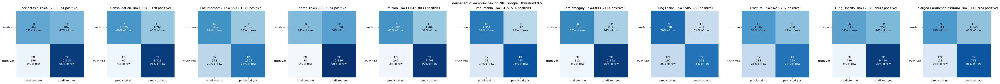

In [163]:
fig, axes = plt.subplots(1, len(FINDINGS), figsize=(4.6 * len(FINDINGS), 4.2), layout="constrained")
for ax, (g, r) in zip(np.atleast_1d(axes), eval_baseline.iterrows()):
    m = np.array([[r.TN, r.FP], [r.FN, r.TP]])
    share = m / np.maximum(m.sum(1, keepdims=True), 1)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for (a, b), n in np.ndenumerate(m):
        name = [["TN", "FP"], ["FN", "TP"]][a][b]
        ax.text(b, a, f"{name}\n{n:,}\n{share[a, b]:.0%} of row", ha="center", va="center", fontsize=10,
                color="white" if share[a, b] > 0.6 else "black")
    ax.set_xticks([0, 1], ["predicted no", "predicted yes"]); ax.set_yticks([0, 1], ["truth no", "truth yes"])
    ax.set_title(f"{g}  (n={r.n:,}, {r.n_pos} positive)", fontsize=11); ax.grid(False)
    ax.spines[:].set_visible(False)
fig.suptitle(f"{WEIGHTS} on NIH Google · threshold {THRESHOLD}", fontsize=12)
plt.show()

**ROC and precision-recall curves.** The dot marks where the model's own threshold sits on each curve.
The dashed line in the PR plot is chance level (= prevalence) for that finding.

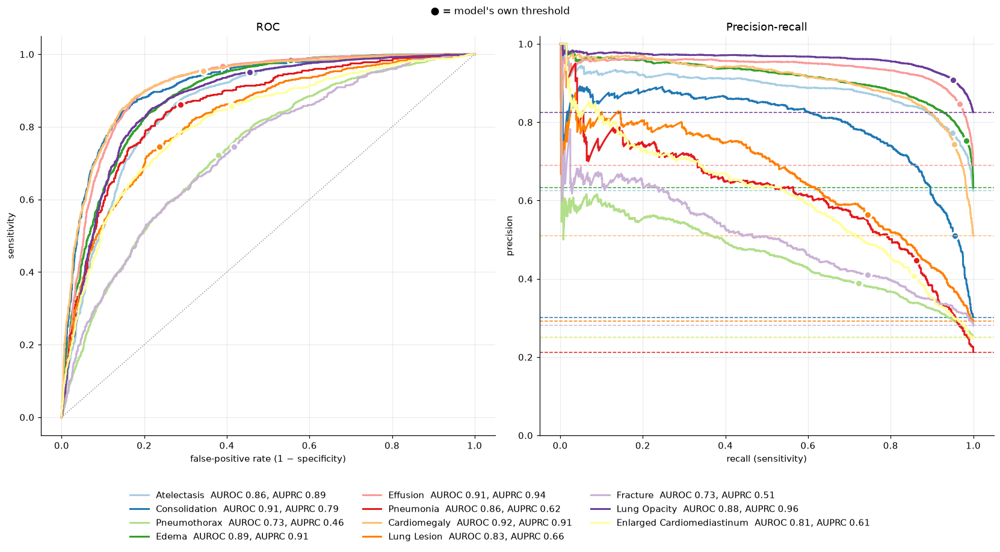

In [164]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 7),
    layout="constrained"
)

for g, m in FINDINGS.items():
    y, s = out_baseline[gcol(g)].to_numpy(), out_baseline[col(m)].to_numpy()
    ok = np.isin(y, [0, 1]) & np.isfinite(s)
    y, s = y[ok].astype(int), s[ok]

    # Skip findings without both positive and negative examples
    if len(np.unique(y)) < 2:
        continue
    r, c = eval_baseline.loc[g], C_FIND[g]
    y, s = np.asarray(y, float), np.asarray(s, float)
    ok = np.isin(y, [0, 1]) & np.isfinite(s)    # NaN = no label (e.g. CheXpert "uncertain")
    y, s = y[ok].astype(int), s[ok]
    fpr, tpr, _ = roc_curve(y, s)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{g}  AUROC {r.auroc:.2f}")
    axes[0].plot(1 - r.specificity, r.sensitivity, "o", ms=8, color=c, mec="white", mew=2)
    prec, rec, _ = precision_recall_curve(y, s)
    axes[1].plot(rec, prec, color=c, lw=2, label=f"{g}  AUPRC {r.auprc:.2f}")
    axes[1].axhline(r.prevalence, color=c, lw=1, ls="--")
    if not np.isnan(r.precision):
        axes[1].plot(r.sensitivity, r.precision, "o", ms=8, color=c, mec="white", mew=2)
axes[0].plot([0, 1], [0, 1], color=C_NEG, lw=1, ls=":")
axes[0].set(xlabel="false-positive rate (1 − specificity)", ylabel="sensitivity", title="ROC")
axes[1].set(xlabel="recall (sensitivity)", ylabel="precision", title="Precision-recall", ylim=(0, 1.02))

handles, labels_AUROC = axes[0].get_legend_handles_labels()
handles, labels_AUPRC = axes[1].get_legend_handles_labels()
labels_both = [labels_AUROC[i] +','+ labels_AUPRC[i][-11:] for i in range(len(labels_AUROC))]

fig.legend(
    handles, labels_both,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=False
)

fig.suptitle("● = model's own threshold", fontsize=11)
plt.show()

**Score distributions.** Where the scores of real positives and real negatives fall relative to the threshold.
Area right of the line: negatives there are FPs, positives left of it are FNs. Both groups are scaled to the
same area, because negatives far outnumber positives.

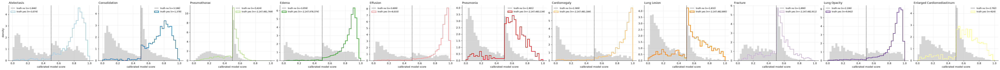

In [165]:
fig, axes = plt.subplots(1, len(FINDINGS), figsize=(5 * len(FINDINGS), 3.8), layout="constrained", sharey=False)
bins = np.linspace(0, 1, 41)
for ax, (g, m) in zip(np.atleast_1d(axes), FINDINGS.items()):
    y, s = out_baseline[gcol(g)].to_numpy(), out_baseline[col(m)].to_numpy()
    ax.hist(s[y == 0], bins=bins, density=True, histtype="stepfilled", alpha=0.35, color=C_NEG, label=f"truth no (n={(y == 0).sum():,})")
    if y.sum():
        ax.hist(s[y == 1], bins=bins, density=True, histtype="step", lw=2, color=C_FIND[g], label=f"truth yes (n={y.sum():,})")
    ax.axvline(THRESHOLD, color="black", lw=1, ls="--")
    ax.set_title(g, loc="left", fontsize=11); ax.set_xlabel("calibrated model score"); ax.legend(frameon=False, fontsize=8.5)
np.atleast_1d(axes)[0].set_ylabel("density")
plt.show()

**Plausibility check against the published numbers.** The library publishes no `-chex` result on this dataset.
The only reference is `-all`, which **trained on most of these images**, so ours should be lower.

## Between 8 and 9 . compare baseline with perturbations

In [146]:
import pickle

out_blurred = {blurring_level : pd.concat([chex, scores_blurred[blurring_level]], axis=1) for blurring_level in blurring_levels}
for blurring_level in blurring_levels:
    for g, m in FINDINGS.items():
        out_blurred[blurring_level][ocol(g)] = outcome(out_blurred[blurring_level][gcol(g)], out_blurred[blurring_level][col(m)])

out_noise = {noise_sd : pd.concat([chex, scores_noise[noise_sd]], axis=1) for noise_sd in noise_sds}
for noise_sd in noise_sds:
    for g, m in FINDINGS.items():
        out_noise[noise_sd][ocol(g)] = outcome(out_noise[noise_sd][gcol(g)], out_noise[noise_sd][col(m)])


with open(os.path.join(WORK, f"blurred_predictions_{TAG}.pkl"), "wb") as f:
    pickle.dump(out_blurred, f)

with open(os.path.join(WORK, f"noise_predictions_{TAG}.pkl"), "wb") as f:
    pickle.dump(out_noise, f)

In [147]:
# evaluation noisy
eval_noise = {noise_sd : evaluate(out_noise[noise_sd]) for noise_sd in noise_sds}

with open(os.path.join(WORK, f"noise_metrics_{TAG}.pkl"), "wb") as f:
    pickle.dump(eval_noise, f)

In [148]:
# evaluation blurred
eval_blurred = {blurring_level : evaluate(out_blurred[blurring_level]) for blurring_level in blurring_levels}

with open(os.path.join(WORK, f"blurred_metrics_{TAG}.pkl"), "wb") as f:
    pickle.dump(eval_blurred, f)

In [149]:
# load results

csv_path = os.path.join(WORK, f"baseline_predictions_{TAG}.csv")
out_baseline = pd.read_csv(csv_path)
csv_path = os.path.join(WORK, f"baseline_metrics_{TAG}.csv")
eval_baseline = pd.read_csv(csv_path)

# Load blurred predictions
with open(os.path.join(WORK, f"blurred_predictions_{TAG}.pkl"), "rb") as f:
    out_blurred = pickle.load(f)

# Load noise predictions
with open(os.path.join(WORK, f"noise_predictions_{TAG}.pkl"), "rb") as f:
    out_noise = pickle.load(f)

# Load blurred metrics
with open(os.path.join(WORK, f"blurred_metrics_{TAG}.pkl"), "rb") as f:
    eval_blurred = pickle.load(f)

# Load noise metrics
with open(os.path.join(WORK, f"noise_metrics_{TAG}.pkl"), "rb") as f:
    eval_noise = pickle.load(f)




In [150]:
def plot_confusion_grid(eval_conditions, findings=FINDINGS):

    n_conditions = len(eval_conditions)
    n_findings = len(findings)

    fig, axes = plt.subplots(
        n_findings, n_conditions,
        figsize=(4.2 * n_conditions, 3.5 * n_findings),
        squeeze=False,
        layout="constrained"
    )

    for j, (condition, results) in enumerate(eval_conditions.items()):

        # Ensure findings are accessible through the index
        if "finding" in results.columns:
            results = results.set_index("finding")

        for i, g in enumerate(findings):

            ax = axes[i, j]
            r = results.loc[g]

            m = np.array([[r.TN, r.FP], [r.FN, r.TP]])
            share = m / np.maximum(m.sum(1, keepdims=True), 1)

            ax.imshow(share, cmap="Blues", vmin=0, vmax=1)

            for (a, b), n in np.ndenumerate(m):
                name = [["TN", "FP"], ["FN", "TP"]][a][b]

                ax.text(
                    b, a,
                    f"{name}\n{n:,}\n{share[a,b]:.0%} of row",
                    ha="center", va="center", fontsize=9,
                    color="white" if share[a,b] > 0.6 else "black"
                )

            ax.set_xticks([0, 1], ["pred. negative", "pred. positive"])
            ax.set_yticks([0, 1], ["truth negative", "truth positive"])

            if i == 0:
                ax.set_title(condition)

            if j == 0:
                ax.set_ylabel(f"{g}\n(n={r.n:,})")

            ax.grid(False)
            ax.spines[:].set_visible(False)

    fig.suptitle(
        f"{WEIGHTS} · Confusion matrices · threshold {THRESHOLD}",
        fontsize=13
    )

    plt.show()

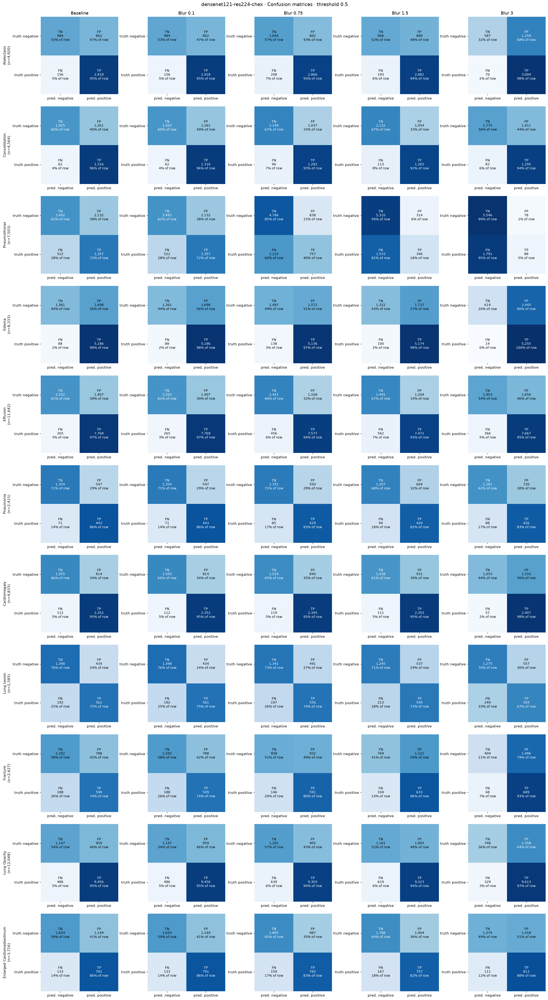

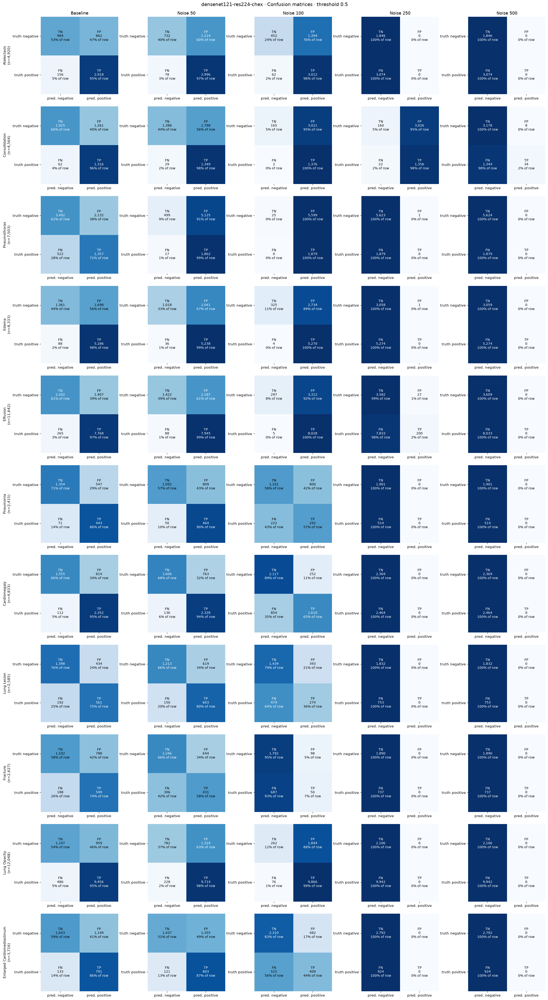

In [168]:
plot_confusion_grid({
    "Baseline": eval_baseline,
    **{f"Blur {level}": eval_blurred[level] for level in blurring_levels}
})

plot_confusion_grid({
    "Baseline": eval_baseline,
    **{f"Noise {sd}": eval_noise[sd] for sd in noise_sds}
})

In [107]:
def plot_score_distributions(eval_conditions, findings=FINDINGS):

    n_conditions = len(eval_conditions)
    n_findings = len(findings)

    fig, axes = plt.subplots(
        n_findings, n_conditions,
        figsize=(4.2 * n_conditions, 3.5 * n_findings),
        squeeze=False,
        sharex=True,
        sharey=True,
        layout="constrained"
    )

    bins = np.linspace(0, 1, 41)

    for j, (condition, results) in enumerate(eval_conditions.items()):
        for i, (g, m) in enumerate(findings.items()):

            ax = axes[i, j]

            y = results[gcol(g)].to_numpy()
            s = results[col(m)].to_numpy()

            valid = np.isin(y, [0, 1]) & np.isfinite(s)
            y, s = y[valid], s[valid]

            n_neg = (y == 0).sum()
            n_pos = (y == 1).sum()

            ax.hist(
                s[y == 0],
                bins=bins,
                density=True,
                histtype="stepfilled",
                alpha=0.35,
                color=C_NEG,
                label=f"truth no (n={n_neg:,})"
            )

            if n_pos:
                ax.hist(
                    s[y == 1],
                    bins=bins,
                    density=True,
                    histtype="step",
                    lw=2,
                    color=C_FIND[g],
                    label=f"truth yes (n={n_pos:,})"
                )

            ax.axvline(
                THRESHOLD,
                color="black",
                lw=1,
                ls="--"
            )

            ax.set_xlim(0, 1)

            if i == 0:
                ax.set_title(condition)

            if j == 0:
                ax.set_ylabel(
                    f"{g}\n(n={len(y):,})\nDensity"
                )

            if i == n_findings - 1:
                ax.set_xlabel("Calibrated model score")

            ax.legend(frameon=False, fontsize=8)

            ax.grid(False)
            ax.spines[:].set_visible(False)

    fig.suptitle(
        f"{WEIGHTS} · Score distributions · threshold {THRESHOLD}",
        fontsize=13
    )

    plt.show()

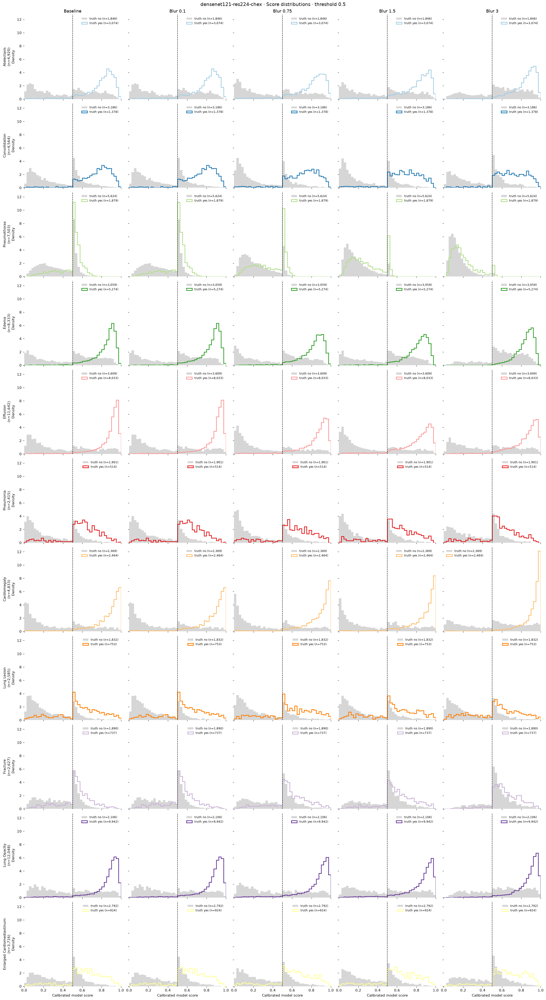

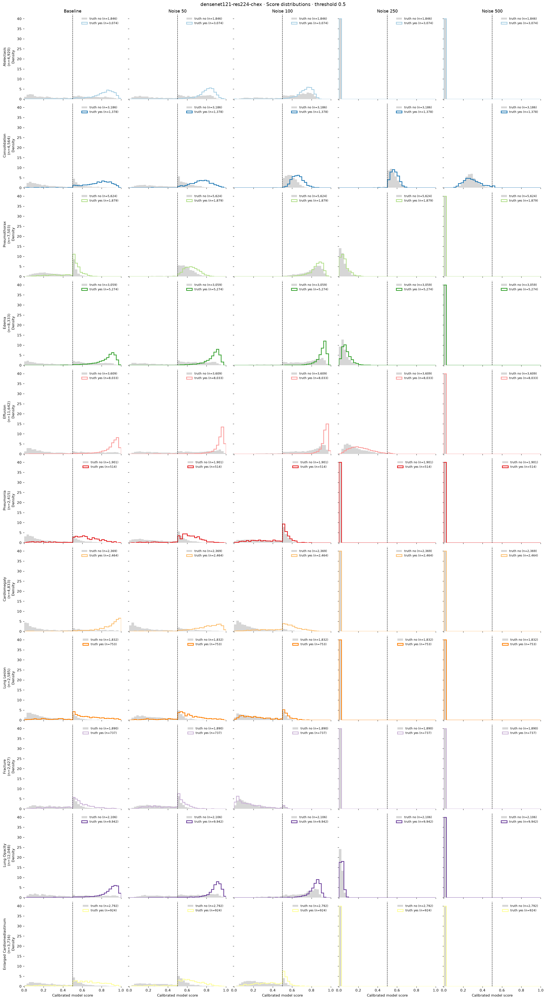

In [152]:
plot_score_distributions({
    "Baseline": out_baseline,
    **{f"Blur {level}": out_blurred[level] for level in blurring_levels}
})
plot_score_distributions({
    "Baseline": out_baseline,
    **{f"Noise {sd}": out_noise[sd] for sd in noise_sds}
})

## Also between 8 and 9: comparing between metadata

In [153]:
selected_races = ["White", "Black", "Asian", "Patient Refused"]
selected_insurance_types = ["Private Insurance","Medicaid"]

out_conditions_sex = {
    sex: chex_scores[chex_scores["sex"] == sex].copy()
    for sex in ["Male","Female"]
}

out_conditions_sex_w_baseline = {
    "Baseline" : chex_scores,
    **out_conditions_sex
}

eval_conditions_sex = {
    "Baseline" : eval_baseline,
    **{
    name: evaluate(df)
    for name, df in out_conditions_sex.items()
    }
}


out_conditions_race = {
    race: chex_scores[chex_scores["race"] == race].copy()
    for race in selected_races
}

out_conditions_race_w_baseline = {
    "Baseline" : chex_scores,
    **out_conditions_race
}

eval_conditions_race = {
    "Baseline" : eval_baseline,
    **{
    name: evaluate(df)
    for name, df in out_conditions_race.items()
    }
}

out_conditions_insurance = {
    insurance_type: chex_scores[chex_scores["insurance_type"] == insurance_type].copy()
    for insurance_type in selected_insurance_types
}

out_conditions_insurance_w_baseline = {
    "Baseline" : chex_scores,
    **out_conditions_insurance
}

eval_conditions_insurance = {
    "Baseline" : eval_baseline,
    **{
    name: evaluate(df)
    for name, df in out_conditions_insurance.items()
    }
}

In [172]:
age_cutoff = 40

out_conditions_age = {
    "age over cutoff": chex_scores[chex_scores["age_years"] >=age_cutoff].copy(),
    "age under cutoff": chex_scores[chex_scores["age_years"] < age_cutoff].copy()
}

out_conditions_age_w_baseline = {
    "Baseline" : chex_scores,
    **out_conditions_age
}

eval_conditions_age = {
    "Baseline" : eval_baseline,
    **{
    name: evaluate(df)
    for name, df in out_conditions_age.items()
    }
}

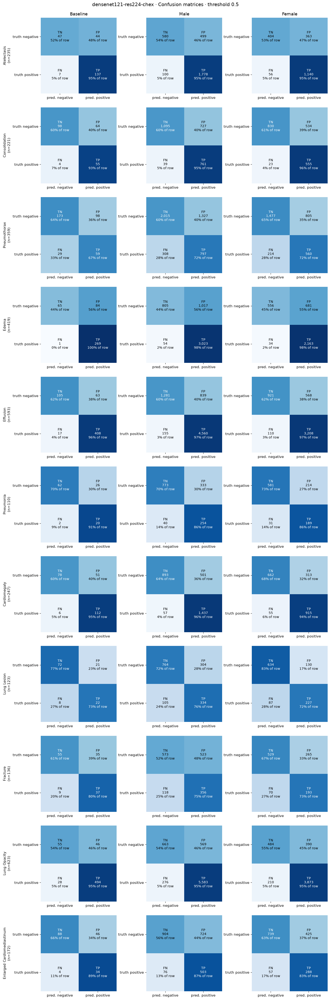

In [166]:
plot_confusion_grid(eval_conditions = eval_conditions_sex)

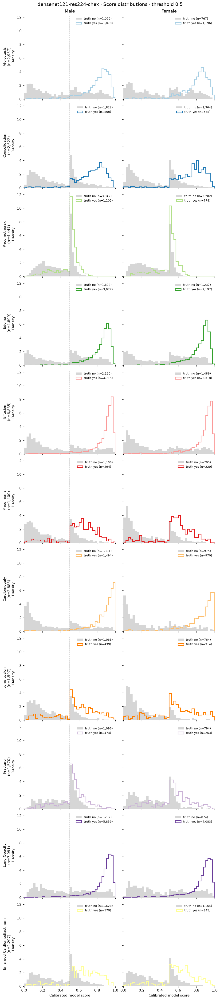

In [155]:
plot_score_distributions(eval_conditions = out_conditions_sex)

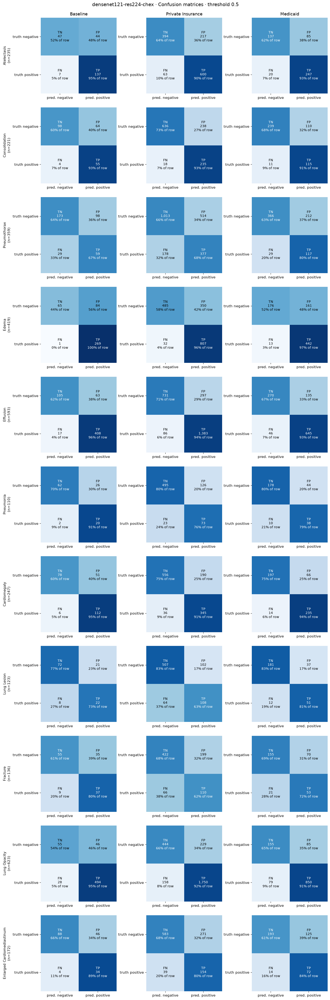

In [156]:
plot_confusion_grid(eval_conditions = eval_conditions_insurance)

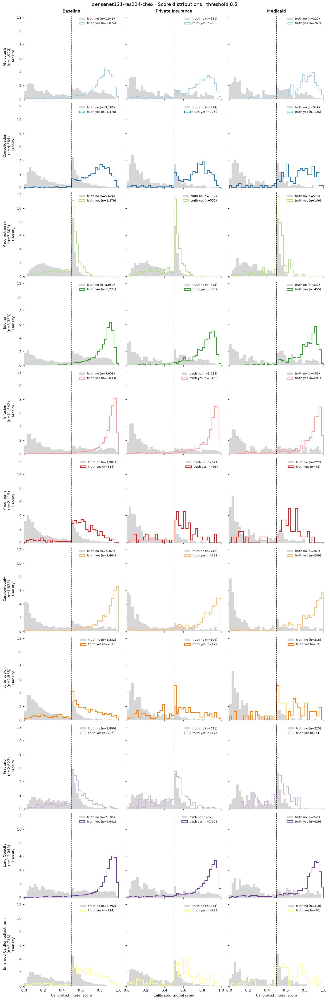

In [157]:
plot_score_distributions(eval_conditions = out_conditions_insurance_w_baseline)

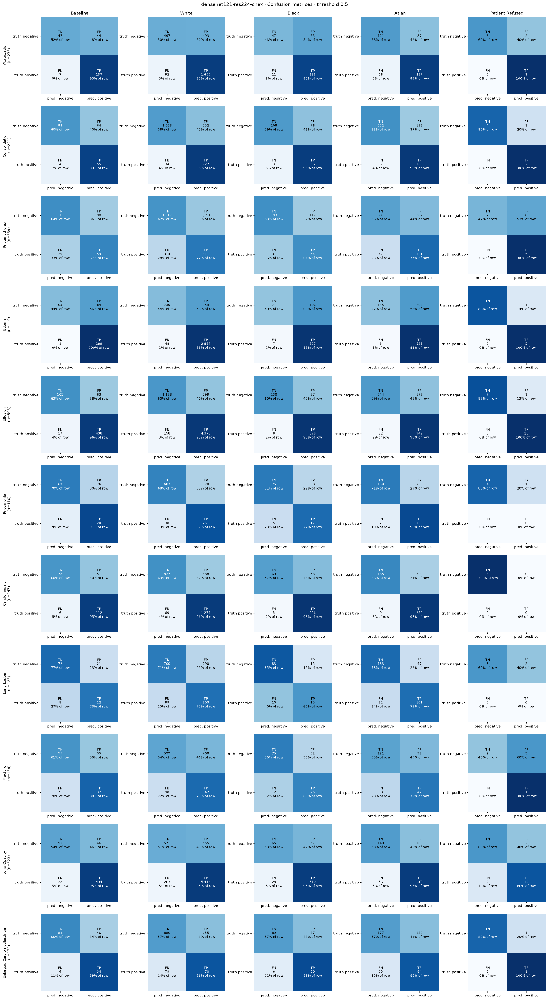

In [158]:
plot_confusion_grid(eval_conditions = eval_conditions_race)

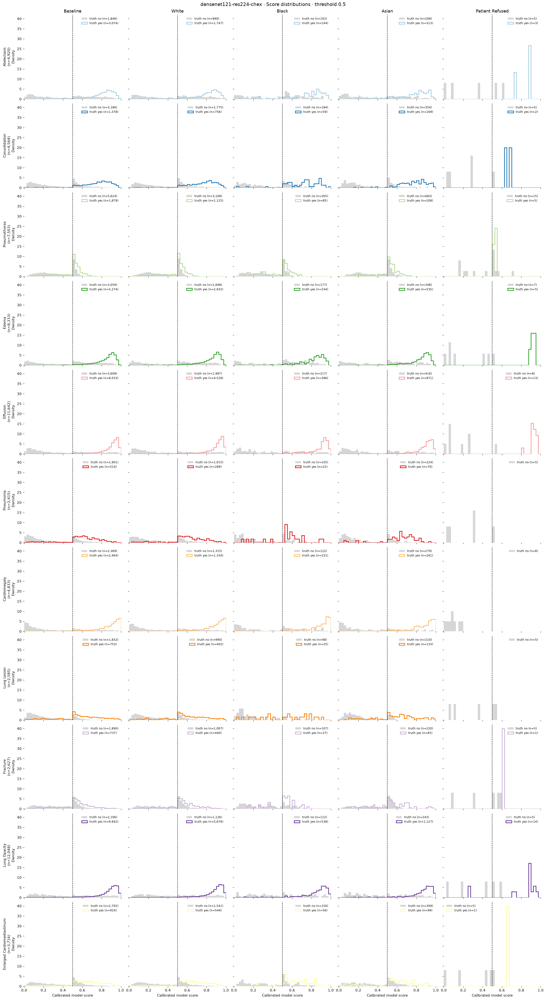

In [159]:
plot_score_distributions(eval_conditions = out_conditions_race_w_baseline)

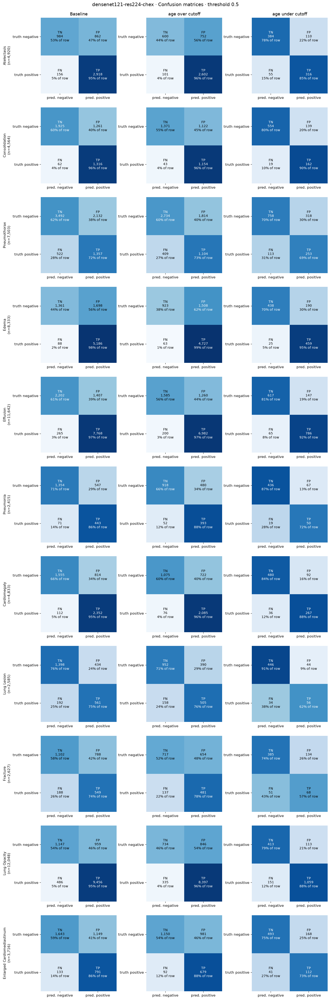

In [173]:
plot_confusion_grid(eval_conditions_age)

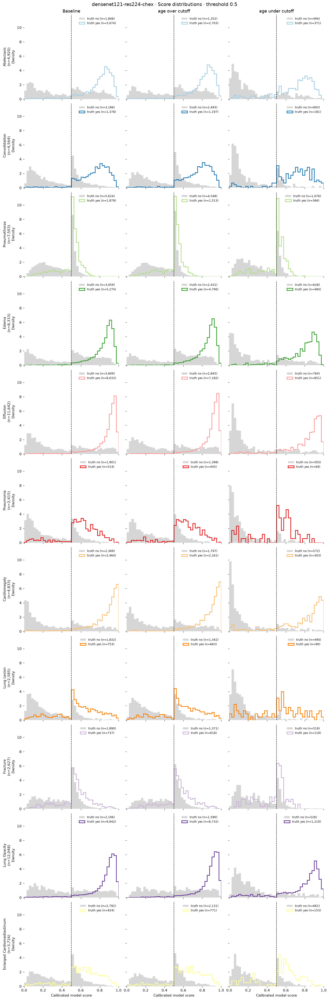

In [174]:
plot_score_distributions(out_conditions_age_w_baseline)

## 9 · Spot check: random images with outcomes
Truth, calibrated score and outcome per finding. Only to see that the numbers match the pictures.

KeyError: 'gt_Pleural_Effusion'

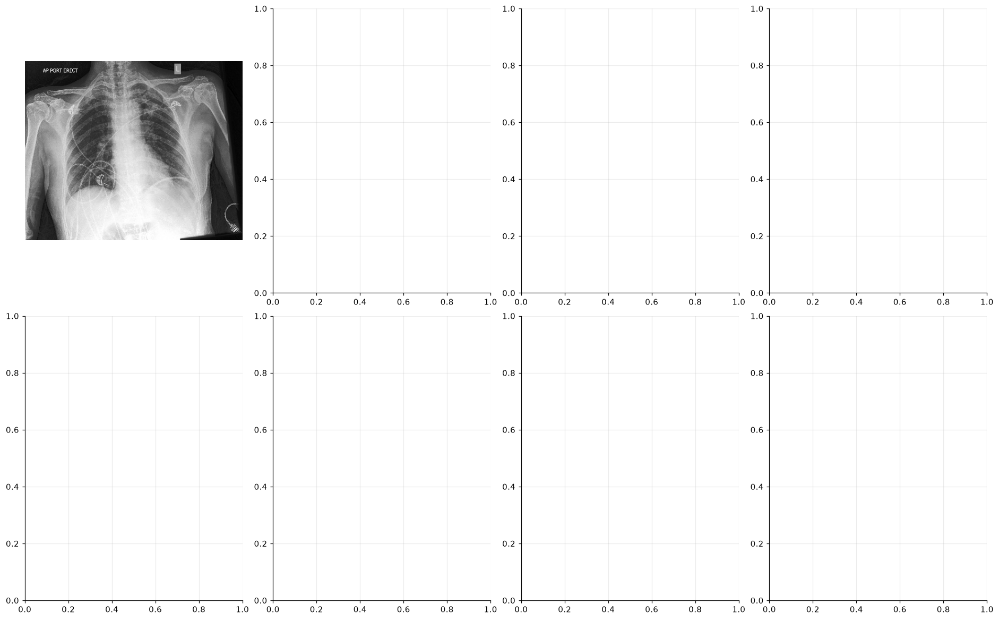

In [ ]:
rng = np.random.default_rng(SEED + 1)
sample = rng.choice(len(out_baseline), min(8, len(out_baseline)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(17, 10.5), layout="constrained")
for ax, i in zip(axes.flat, sample):
    r = out_baseline.iloc[i]
    ax.imshow(load_raw(r.image_id[26:]), cmap="gray"); ax.axis("off")
    lines = [f"{r.image_i[26:]d} · {r['view']} · {r.sex} {r.age}"]
    for g, m in FINDINGS.items():
        lines.append(f"{g:<13} truth {int(r[gcol(g)])}  score {r[col(m)]:.2f}  {r[ocol(g)]}")
    ax.set_title("\n".join(lines), fontsize=8.5, family="monospace", loc="left")
for ax in axes.flat[len(sample):]:
    ax.axis("off")
fig.suptitle(f"{WEIGHTS}: 8 random images", fontsize=12)
plt.show()

## 10 · Second baseline: NIH's own labels (noisy)
The same images also carry NIH's labels, mined automatically from the report text. They cover 7 of the model's
outputs, but they are **noisy**: for Pneumothorax, NIH and Google agree on only about half the positives (section 3).
A "false positive" here can just as well be a labelling error. Use it as a second reference, not as truth.

In [281]:
ncol = lambda g: "nihlab_" + g.replace(" ", "_")
nih_sets = out.nih_finding_labels.str.split("|").apply(set)
for g in NIH_FINDINGS:
    out_baseline[ncol(g)] = nih_sets.apply(lambda ls: int(g in ls))

baseline_nih = evaluate(out_baseline, NIH_FINDINGS, truth=ncol)
baseline_nih.to_csv(os.path.join(WORK, f"baseline_metrics_{TAG}_nihlabels.csv"), float_format="%.4f")
show_table(baseline_nih)

,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Pneumonia,Pneumothorax
positives / labelled,127 / 1000 (12.7%),63 / 1000 (6.3%),91 / 1000 (9.1%),37 / 1000 (3.7%),177 / 1000 (17.7%),30 / 1000 (3.0%),80 / 1000 (8.0%)
auroc,0.553 [0.498–0.609],0.570 [0.492–0.638],0.667 [0.610–0.722],0.667 [0.567–0.757],0.669 [0.620–0.716],0.543 [0.450–0.636],0.610 [0.539–0.677]
auprc,0.134 [0.109–0.175],0.076 [0.052–0.114],0.147 [0.110–0.204],0.068 [0.040–0.139],0.255 [0.198–0.326],0.036 [0.023–0.065],0.117 [0.079–0.175]
sensitivity,0.882 [0.823–0.939],0.794 [0.659–0.908],0.934 [0.863–0.985],0.919 [0.816–1.000],0.887 [0.829–0.934],0.667 [0.500–0.833],0.287 [0.183–0.398]
specificity,0.223 [0.190–0.259],0.352 [0.311–0.395],0.307 [0.267–0.349],0.160 [0.131–0.192],0.348 [0.307–0.392],0.360 [0.317–0.403],0.789 [0.757–0.825]
precision,0.142 [0.116–0.171],0.076 [0.051–0.105],0.119 [0.089–0.150],0.040 [0.028–0.053],0.226 [0.181–0.271],0.031 [0.019–0.046],0.106 [0.064–0.153]
FP / FN,678 / 15,607 / 13,630 / 6,809 / 3,537 / 20,621 / 10,194 / 57


## 11 · Output baseline: all 11 outputs (no labels needed)
What the model *says*, regardless of whether it is right. This is the reference for perturbations: if a change to
the images moves the Edema score, you see it here even though Edema has no label.

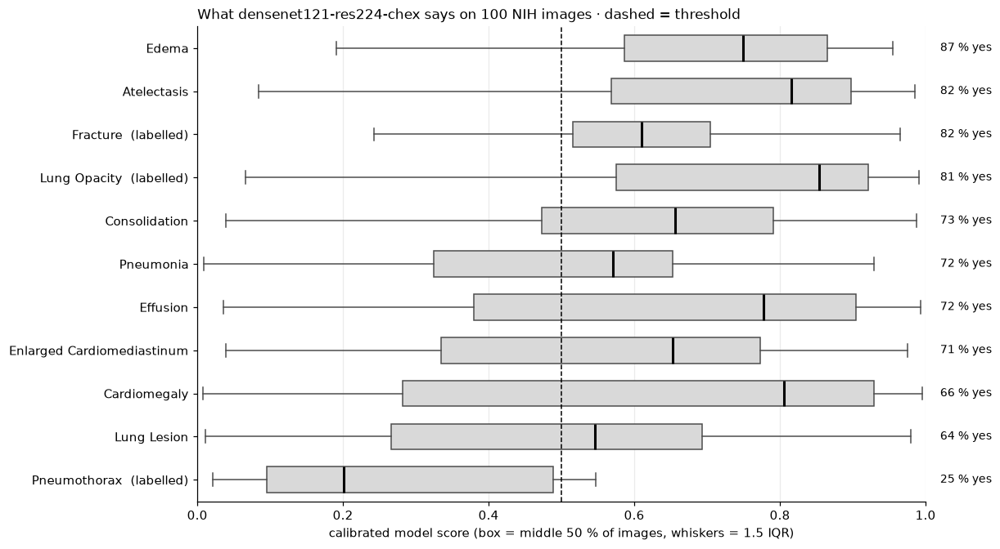

,% says yes,mean score,median score
Pneumothorax,25.0,0.260,0.201
Lung Lesion,64.0,0.498,0.546
Cardiomegaly,66.0,0.636,0.806
Enlarged Cardiomediastinum,71.0,0.582,0.653
Effusion,72.0,0.642,0.777
Pneumonia,72.0,0.492,0.570
Consolidation,73.0,0.583,0.656
Lung Opacity,81.0,0.729,0.854
Fracture,82.0,0.592,0.611
Atelectasis,82.0,0.703,0.815


In [ ]:
def output_profile(df, thr=THRESHOLD):
    return pd.DataFrame({l: {"% says yes": 100 * (df[col(l)] > thr).mean(), "mean score": df[col(l)].mean(),
                             "median score": df[col(l)].median()} for l in labels}).T

baseline_profile = output_profile(out_baseline).sort_values("% says yes")
baseline_profile.to_csv(os.path.join(WORK, f"baseline_outputs_{TAG}.csv"), float_format="%.4f")

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.boxplot([out_baseline[col(l)] for l in baseline_profile.index], vert=False, widths=0.6, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#d9d9d9", color="#4d4d4d"),
           medianprops=dict(color="black", lw=2), whiskerprops=dict(color="#4d4d4d"), capprops=dict(color="#4d4d4d"))
ax.set_yticks(range(1, len(baseline_profile) + 1), [f"{l}{'  (labelled)' if l in FINDINGS.values() else ''}" for l in baseline_profile.index])
ax.axvline(THRESHOLD, color="black", lw=1, ls="--")
for k, (l, r) in enumerate(baseline_profile.iterrows(), start=1):
    ax.text(1.02, k, f"{r['% says yes']:.0f} % yes", va="center", fontsize=9, transform=ax.get_yaxis_transform())
ax.set_xlim(0, 1); ax.set_xlabel("calibrated model score (box = middle 50 % of images, whiskers = 1.5 IQR)")
ax.set_title(f"What {WEIGHTS} says on {len(out_baseline):,} NIH images · dashed = threshold", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.show()
baseline_profile.round(3)

**Comparing a perturbed run with the baseline.** Two helpers, used the same way for every perturbation:
- `compare_runs(base, pert)`: per output, how far the scores move and how many images flip across the threshold.
- `outcome_flips(base, pert)`: per labelled finding, how outcomes move, e.g. how many TN became FP.

Usage (the perturbation itself is up to each pair):
```python
pert_ds  = nih_dataset(torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),
                                                       xrv.datasets.XRayResizer(224),
                                                       MyPerturbation()]))
pert     = run_model(pert_ds, "my perturbation")
compare_runs(out, pert)                                # all 11 outputs
outcome_flips(out, pert)                               # 3 labelled findings
evaluate(pd.concat([nih, pert], axis=1))               # same metrics as the main baseline
```
The check below runs the first images through the same pipeline again, without any change. Nothing may move.

In [ ]:
def compare_runs(base, pert, thr=THRESHOLD):
    # base, pert: the same images in the same order, both with chex__ score columns
    assert len(base) == len(pert)
    rows = {}
    for l in labels:
        b, p = base[col(l)].to_numpy(float), pert[col(l)].to_numpy(float)
        rows[l] = {"mean before": b.mean(), "mean after": p.mean(), "mean shift": (p - b).mean(),
                   "mean |shift|": np.abs(p - b).mean(),
                   "% yes before": 100 * (b > thr).mean(), "% yes after": 100 * (p > thr).mean(),
                   "flips no→yes": int(((b <= thr) & (p > thr)).sum()),
                   "flips yes→no": int(((b > thr) & (p <= thr)).sum())}
    return pd.DataFrame(rows).T

def outcome_flips(base, pert, findings=FINDINGS, truth=gcol, thr=THRESHOLD):
    # per labelled finding: outcome before (rows) vs. after (columns)
    order = ["TP", "FN", "TN", "FP"]
    res = {}
    for g, m in findings.items():
        y = base[truth(g)].to_numpy()
        res[g] = pd.crosstab(pd.Series(outcome(y, base[col(m)], thr), name="before"),
                             pd.Series(outcome(y, pert[col(m)], thr), name="after")).reindex(
                             index=order, columns=order, fill_value=0)
    return res

n_check = min(64, len(ds_bootstrap))
again = run_model(xrv.datasets.SubsetDataset(ds_bootstrap, list(range(n_check))), "re-run", every=0)
check = compare_runs(out_baseline.iloc[:n_check].reset_index(drop=True), again)
assert check["mean |shift|"].max() < 1e-4, check
print(f"check passed: re-running {n_check} images gives the same scores "
      f"(max mean |shift| = {check['mean |shift|'].max():.1e})")

re-run done: 64 images in 8s
check passed: re-running 64 images gives the same scores (max mean |shift| = 0.0e+00)


## 12 · CheXpert baseline: the model on its own hospital
Ground truth for **all 11 outputs**, on two sets the model did **not** train on:

| Set | Images | Labels | Why not seen in training |
|---|---|---|---|
| **valid** (official) | 234 (202 frontal), 200 patients | **radiologists** (3, majority vote) | the training script reads only `train.csv` |
| **held-out 20 %** | ≈ 5,800 PA images (with `CHEX_HELDOUT_VIEWS = ["PA"]`) | text-mined, with "uncertain" → no label | the training script holds out 20 % of patients (`GroupShuffleSplit`, seed 0). Rebuilt here with the same settings |

Caveats: valid has **no fracture** and only 1 Lung Lesion, so those stay empty there. The held-out set is a
**reconstruction**. The check below compares it with the thresholds the authors computed on *their* held-out set
(`scripts/model_calibrate.py`: Youden index on the 20 %). Near-identical thresholds mean the split (and the PA-only
setting) is right. Clear differences mean the published weights were made with other settings: then try
`CHEX_HELDOUT_VIEWS = ["PA", "AP"]`. Small differences can also come from preprocessing details.

In [290]:
import sklearn.model_selection
transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(),
                                            xrv.datasets.XRayResizer(224)])
xcol = lambda g: "cxlab_" + g.replace(" ", "_")
CHEX_FINDINGS = {l: l for l in labels}                 # CheXpert labels cover all 11 outputs
baseline_chex_valid = baseline_chex_heldout = None

def chex_table(cds, rows):
    c = cds.csv.iloc[rows].reset_index(drop=True)
    t = pd.DataFrame({"path": c.Path, "patient_id": "patient" + c.patientid, "view": c['view'],
                      "sex": c.Sex, "age": c.Age})
    for j, p in enumerate(cds.pathologies):
        if p in CHEX_FINDINGS:
            t[xcol(p)] = cds.labels[rows, j]
    return t

def available(cds, rows):
    # on Kaggle every image is there; locally only the few sample images
    if ON_KAGGLE:
        return np.asarray(rows)
    rel = cds.csv.Path.iloc[rows].str.replace("CheXpert-v1.0-small/", "", regex=False)
    return np.asarray(rows)[[os.path.exists(os.path.join(CHEX_DIR, p)) for p in rel]]

if not (RUN_CHEX_EVAL and CHEX_DIR):
    print("Skipped (RUN_CHEX_EVAL is False or no CheXpert images attached).")
else:
    # a) official validation set, all frontal images
    cv = xrv.datasets.CheX_Dataset(imgpath=CHEX_DIR, csvpath=os.path.join(CHEX_DIR, "valid.csv"),
                                   views=["PA", "AP"], unique_patients=False, transform=transform)
    rows_v = available(cv, np.arange(len(cv)))
    chex_valid = pd.concat([chex_table(cv, rows_v),
                            run_model(xrv.datasets.SubsetDataset(cv, list(rows_v)), "CheXpert valid")], axis=1)

    # b) held-out 20 %: same loader settings and split as scripts/train_model.py
    ct = xrv.datasets.CheX_Dataset(imgpath=CHEX_DIR, csvpath=os.path.join(CHEX_DIR, "train.csv"),
                                   views=CHEX_HELDOUT_VIEWS, unique_patients=False, transform=transform)
    gss = sklearn.model_selection.GroupShuffleSplit(train_size=0.8, test_size=0.2, random_state=0)
    train_inds, test_inds = next(gss.split(X=range(len(ct)), groups=ct.csv.patientid))
    print(f"reconstructed split {CHEX_HELDOUT_VIEWS}: {len(train_inds):,} training / {len(test_inds):,} held-out images")
    rows_h = available(ct, test_inds)
    chex_heldout = pd.concat([chex_table(ct, rows_h),
                              run_model(xrv.datasets.SubsetDataset(ct, list(rows_h)), "CheXpert held-out", every=50)],
                             axis=1)

    chex_valid.to_csv(os.path.join(WORK, "predictions_chexpert_valid.csv"), index=False, float_format="%.6f")
    chex_heldout.to_csv(os.path.join(WORK, "predictions_chexpert_heldout.csv"), index=False, float_format="%.6f")

CheXpert valid     32 / 202  4s


KeyboardInterrupt: 

In [ ]:
# check: Youden-index threshold on our held-out set vs. the published op_threshs
if RUN_CHEX_EVAL and CHEX_DIR:
    rows = {}
    for l, t_pub in zip(labels, op_threshs):
        y = chex_heldout[xcol(l)].to_numpy(float)
        s = chex_heldout[col(l) + "__raw"].to_numpy(float)
        ok = ~np.isnan(y)
        t_ours = np.nan
        if 0 < y[ok].sum() < ok.sum():
            fpr, tpr, thr = roc_curve(y[ok], s[ok])
            t_ours = thr[np.argmax(tpr - fpr)]
        rows[l] = {"published op_thresh": t_pub, "ours (held-out)": t_ours, "difference": t_ours - t_pub,
                   "labelled images": int(ok.sum())}
    display(pd.DataFrame(rows).T.round(5))

In [ ]:
if RUN_CHEX_EVAL and CHEX_DIR:
    baseline_chex_valid = evaluate(chex_valid, CHEX_FINDINGS, truth=xcol)
    baseline_chex_heldout = evaluate(chex_heldout, CHEX_FINDINGS, truth=xcol)
    baseline_chex_valid.to_csv(os.path.join(WORK, "baseline_metrics_chexpert_valid.csv"), float_format="%.4f")
    baseline_chex_heldout.to_csv(os.path.join(WORK, "baseline_metrics_chexpert_heldout.csv"), float_format="%.4f")
    print("CheXpert valid (radiologist labels)")
    display(show_table(baseline_chex_valid))
    print("CheXpert held-out 20 % (text-mined labels)")
    display(show_table(baseline_chex_heldout))

## 13 · All baselines in one view
AUROC with 95 % CI per model output and test set. **Colour = hospital** (blue NIH, orange CheXpert),
**filled = radiologist labels**, hollow = text-mined labels. Gaps between blue and orange show what changes when
the model leaves its own hospital. Gaps between filled and hollow show how much the label source matters.

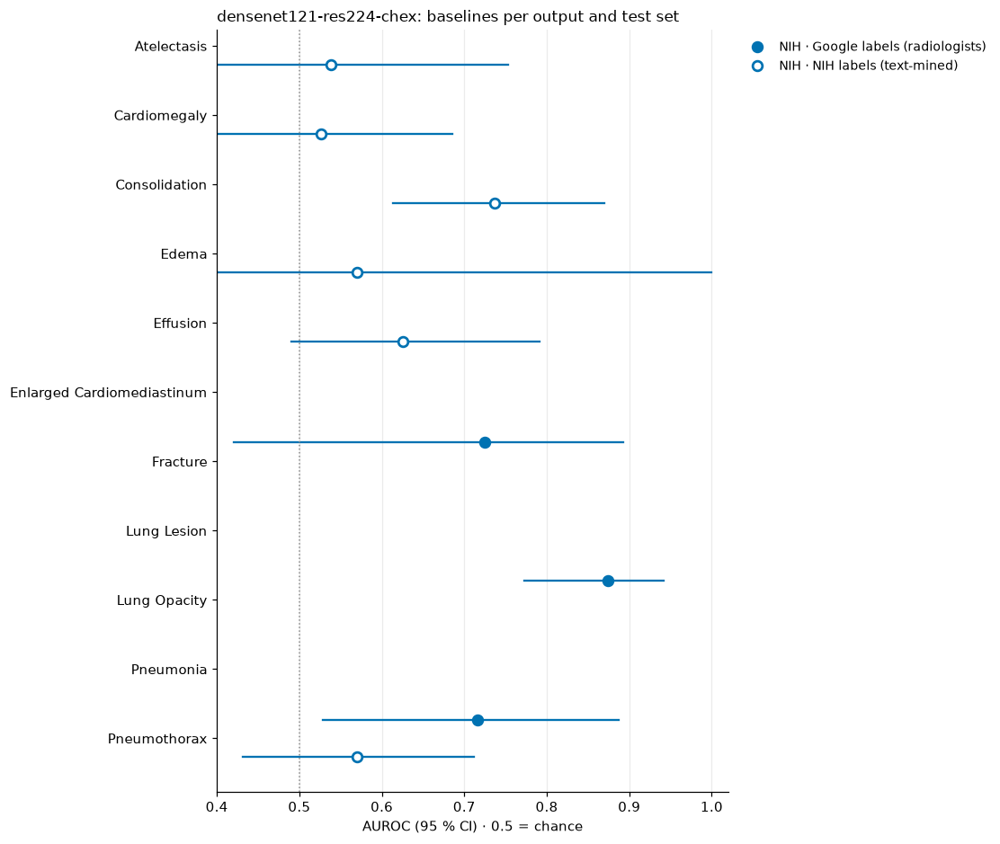

In [ ]:
SETS = {"NIH · Google labels (radiologists)": (baseline, C_DATA["NIH Google (test)"], "o", True),
        "NIH · NIH labels (text-mined)": (baseline_nih, C_DATA["NIH Google (test)"], "o", False),
        "CheXpert · valid (radiologists)": (baseline_chex_valid, C_DATA["CheXpert (training)"], "s", True),
        "CheXpert · held-out 20 % (text-mined)": (baseline_chex_heldout, C_DATA["CheXpert (training)"], "s", False)}
SETS = {k: v for k, v in SETS.items() if v[0] is not None}

long = pd.concat([b.reset_index().assign(test_set=k) for k, (b, *_ ) in SETS.items()], ignore_index=True)
long.to_csv(os.path.join(WORK, f"baseline_all_{TAG}.csv"), index=False, float_format="%.4f")

order = sorted(labels)
fig, ax = plt.subplots(figsize=(10, 0.62 * len(order) + 1.6), layout="constrained")
offsets = np.linspace(-0.27, 0.27, len(SETS))
for off, (name, (b, c, mk, filled)) in zip(offsets, SETS.items()):
    b = b.set_index("model_output")
    for k, l in enumerate(order):
        if l in b.index and not np.isnan(b.loc[l, "auroc"]):
            r = b.loc[l]
            ax.plot([r.auroc_lo, r.auroc_hi], [k + off] * 2, color=c, lw=1.5)
            ax.plot(r.auroc, k + off, mk, ms=7, color=c, mfc=c if filled else "white", mew=1.8, clip_on=False)
    ax.plot([], [], mk, ms=7, color=c, mfc=c if filled else "white", mew=1.8, label=name)
ax.axvline(0.5, color=C_NEG, lw=1, ls=":")
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
ax.set_xlim(0.4, 1.02); ax.set_xlabel("AUROC (95 % CI) · 0.5 = chance")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_title(f"{WEIGHTS}: baselines per output and test set", loc="left", fontsize=11)
plt.show()

## 14 · Save run info and optional 512 px copies

In [ ]:
info = {"weights": WEIGHTS, "torchxrayvision": xrv.__version__, "torch": torch.__version__,
        "repo_commit": "17726dd8f5e756eec3e5ae958281a289b05b1dae", "device": device,
        "n_images": len(out), "n_patients": int(out.patient_id.nunique()), "limit": LIMIT,
        "views": out['view'].value_counts().to_dict(), "outputs": labels,
        "op_threshs": dict(zip(labels, model.op_threshs[keep].tolist())),
        "threshold": THRESHOLD, "findings": FINDINGS, "nih_findings": NIH_FINDINGS, "n_boot": N_BOOT, "seed": SEED,
        "chexpert_eval": bool(RUN_CHEX_EVAL and CHEX_DIR), "chexpert_heldout_views": CHEX_HELDOUT_VIEWS,
        "chexpert_source": CHEX_SOURCE,
        "created": time.strftime("%Y-%m-%d %H:%M"), "python": platform.python_version()}
json.dump(info, open(os.path.join(WORK, "run_info.json"), "w"), indent=2)

if SAVE_THUMBS:
    tdir = os.path.join("/tmp", "nih_google_512")
    shutil.rmtree(tdir, ignore_errors=True); os.makedirs(tdir)
    for i, f in enumerate(out.image_id):
        im = Image.open(chex_path[f]).convert("L")
        im.thumbnail((THUMB_SIZE, THUMB_SIZE), Image.LANCZOS)
        im.save(os.path.join(tdir, f), optimize=True)
        if i % 500 == 0: print(i, "/", len(out))
    shutil.make_archive(os.path.join(WORK, "nih_google_512"), "zip", tdir)

for f in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f)
    if os.path.isfile(p): print(f"{f:32s} {os.path.getsize(p) / 1e6:8.1f} MB")

0 / 100
baseline_all_chex.csv                 0.0 MB
baseline_metrics_chex.csv             0.0 MB
baseline_metrics_chex_nihlabels.csv      0.0 MB
baseline_outputs_chex.csv             0.0 MB
nih_google_512.zip                    2.1 MB
predictions_chex.csv                  0.0 MB
run_info.json                         0.0 MB
